In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [2]:
image = cv2.imread('sar_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

1. Подберите параметры алгоритма разрастания регионов так, чтобы был выделен весь участок газона.

In [3]:
def homo_average(img, mask, point, T):
    region_pixels = img[mask == 1]

    if region_pixels.size == 0:
        return False

    region_mean = np.mean(region_pixels)
    pixel_value = img[point]

    return abs(float(pixel_value) - region_mean) < T

In [6]:
def region_growing(img, seed_point, homo_fun, r, T):
    h, w = img.shape
    mask = np.zeros((h, w), dtype=np.uint8)
    mask[seed_point] = 1
    frontier = [seed_point]

    while frontier:
        y, x = frontier.pop()

        for dy in range(-r, r + 1):
            for dx in range(-r, r + 1):
                ny, nx = y + dy, x + dx

                if ny < 0 or ny >= h or nx < 0 or nx >= w:
                    continue

                if mask[ny, nx] == 1:
                    continue

                if homo_fun(img, mask, (ny, nx), T):
                    mask[ny, nx] = 1
                    frontier.append((ny, nx))

    return mask * 255

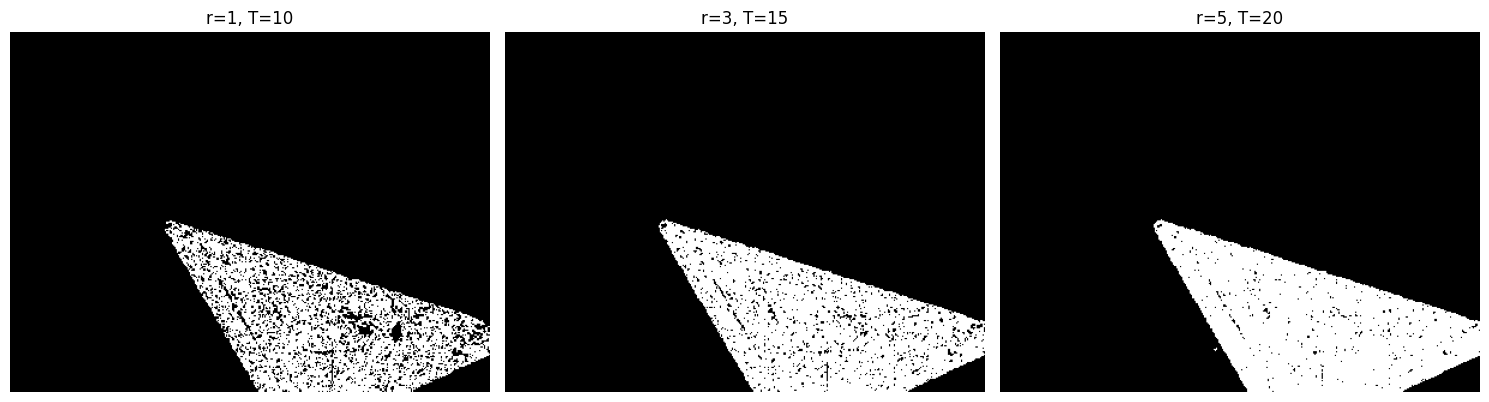

In [7]:
seed_point = (250, 250)
parameters = [(1, 10), (3, 15), (5, 20)]

fig, axes = plt.subplots(1, len(parameters), figsize=(15, 5))

for ax, (r, T) in zip(axes, parameters):
    result = region_growing(image_gray, seed_point, homo_average, r, T)
    ax.imshow(result, cmap="gray")
    ax.set_title(f"r={r}, T={T}")
    ax.axis("off")

plt.tight_layout()
plt.show()

2. Реализуйте вычисление критерия однородности, отличного от представленного. Сравните результаты.

In [8]:
def homo_median(img, mask, point, T):
    region_pixels = img[mask == 1]

    if region_pixels.size == 0:
        return False

    region_median = np.median(region_pixels)
    pixel_value = img[point]

    return abs(float(pixel_value) - float(region_median)) < T

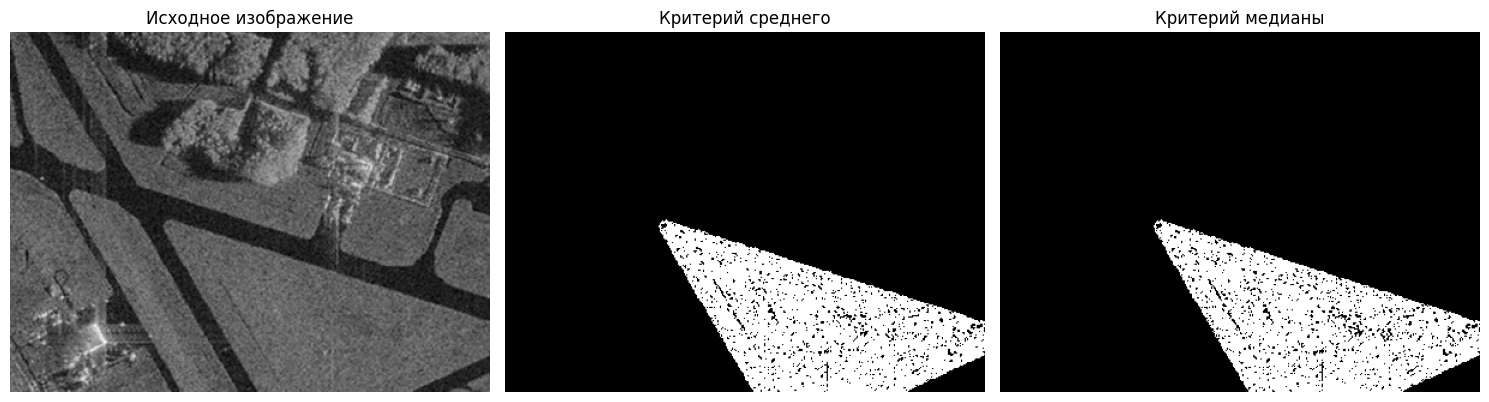

In [9]:
seed_point = (250, 250)
r, T = 3, 15

mask_mean = region_growing(
    image_gray, seed_point, homo_average, r, T
)

mask_median = region_growing(
    image_gray, seed_point, homo_median, r, T
)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image_gray, cmap="gray")
axes[0].set_title("Исходное изображение")

axes[1].imshow(mask_mean, cmap="gray")
axes[1].set_title("Критерий среднего")

axes[2].imshow(mask_median, cmap="gray")
axes[2].set_title("Критерий медианы")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

3. Применить алгоритм сегментации watershed+distance transform для задачи подсчета пальмовых деревьев.

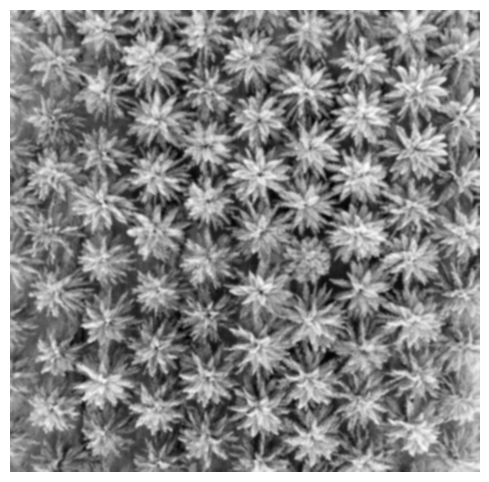

In [13]:
image = cv2.imread("palm_1.JPG")

if image is None:
    raise FileNotFoundError("Не удалось загрузить palm_1.JPG")

image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
image_blur = cv2.GaussianBlur(image_gray, (5, 5), 0)

plt.figure(figsize=(8, 6))
plt.imshow(image_blur, cmap="gray")
plt.axis("off")
plt.show()

In [14]:
def count_palms(image, gray, coefficient):
    _, binary = cv2.threshold(
        gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
    )

    distance = cv2.distanceTransform(binary, cv2.DIST_L2, 5)

    _, foreground = cv2.threshold(
        distance,
        coefficient * distance.max(),
        255,
        cv2.THRESH_BINARY
    )

    foreground = foreground.astype(np.uint8)

    _, markers = cv2.connectedComponents(foreground)
    markers = markers.astype(np.int32)

    markers = cv2.watershed(image.copy(), markers)

    # Метка -1 соответствует границам watershed,
    # метка 1 — фону; остальные метки — сегментам объектов.
    labels = np.unique(markers)
    object_labels = labels[labels > 1]

    return len(object_labels), markers

In [17]:
for coefficient in np.arange(0.1, 0.71, 0.05):
    number, _ = count_palms(image, image_blur, float(coefficient))
    print(f"Коэффициент: {coefficient:.2f}. Число деревьев: {number}")

Коэффициент: 0.10. Число деревьев: 227
Коэффициент: 0.15. Число деревьев: 246
Коэффициент: 0.20. Число деревьев: 247
Коэффициент: 0.25. Число деревьев: 291
Коэффициент: 0.30. Число деревьев: 262
Коэффициент: 0.35. Число деревьев: 230
Коэффициент: 0.40. Число деревьев: 194
Коэффициент: 0.45. Число деревьев: 143
Коэффициент: 0.50. Число деревьев: 105
Коэффициент: 0.55. Число деревьев: 79
Коэффициент: 0.60. Число деревьев: 52
Коэффициент: 0.65. Число деревьев: 34
Коэффициент: 0.70. Число деревьев: 16


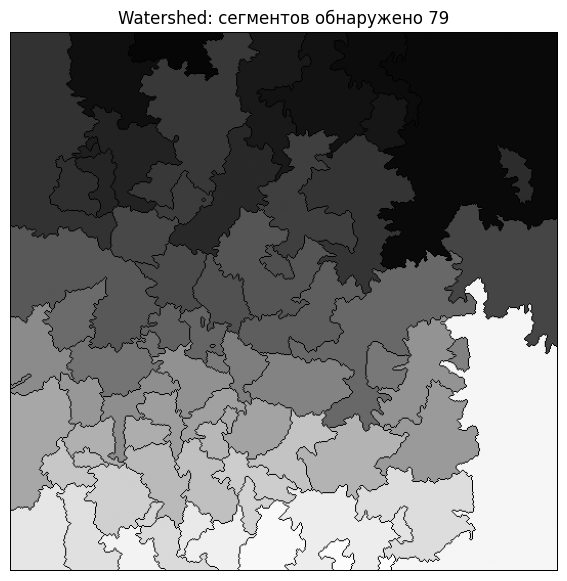

Число обнаруженных сегментов: 79


In [19]:
coefficient = 0.55

number, markers = count_palms(image, image_blur, coefficient)

plt.figure(figsize=(10, 7))
plt.imshow(markers, cmap="gray")
plt.title(f"Watershed: сегментов обнаружено {number}")
plt.axis("off")
plt.show()

print("Число обнаруженных сегментов:", number)

При коэфициенте 0.55 результат наиболее приближен к реальному числу